#  Data Cleaning
**Purpose:** Find and fix data-quality problems: gaps, sensor errors, and an inconsistent early period.

**Input:** `data/cleaned/delhi_merged.csv`

**Output:** `data/cleaned/delhi_clean.csv` (1,195 rows)

## 1. Load merged data

In [1]:
from pathlib import Path
import pandas as pd, numpy as np

BASE = Path.cwd().parent
df = pd.read_csv(BASE / "data" / "cleaned" / "delhi_merged.csv", parse_dates=["Date"])
df = df.set_index("Date")
print(df.shape)       

(2009, 19)


## 2. Diagnose: long gaps, yearly shifts, suspicious zeros

In [2]:
def long_gaps(s, min_len=7):
    isna = s.isna()
    grp = (isna != isna.shift()).cumsum()
    out = []
    for _, g in s.groupby(grp):
        if g.isna().all() and len(g) >= min_len:
            out.append((g.index[0].date(), g.index[-1].date(), len(g)))
    return out

for c in ["PM10", "SO2", "O3", "NH3"]:
    print(c, long_gaps(df[c]))

# era-shift check: yearly mean and spread
print(df.groupby(df.index.year)[["O3", "NO2", "PM2.5", "CO"]].agg(["mean", "std"]).round(1))

# suspicious zeros
print((df[["NOx", "CO", "Benzene", "Toluene"]] == 0).sum())

PM10 [(datetime.date(2015, 12, 15), datetime.date(2015, 12, 21), 7), (datetime.date(2017, 7, 4), datetime.date(2017, 8, 30), 58)]
SO2 [(datetime.date(2017, 6, 8), datetime.date(2017, 8, 27), 81), (datetime.date(2017, 8, 29), datetime.date(2017, 9, 25), 28)]
O3 [(datetime.date(2017, 6, 8), datetime.date(2017, 8, 27), 81)]
NH3 []
        O3         NO2        PM2.5          CO     
      mean   std  mean   std   mean    std mean  std
Date                                                
2015  57.4  26.9  50.4  21.1  117.3   63.1  5.3  4.6
2016  76.9  35.5  63.5  28.6  138.5  100.0  1.6  0.7
2017  42.2  16.9  57.7  24.2  125.1   89.6  0.7  0.6
2018  44.4  12.9  45.9  16.2  115.0   75.8  1.4  0.6
2019  38.9  11.7  45.2  14.6  108.5   85.5  1.4  0.5
2020  40.6  11.8  33.2  13.8   80.3   55.9  1.1  0.4
NOx          2
CO          87
Benzene      8
Toluene    108
dtype: int64


## 3. Locate the level shift (monthly means and 30-day trends)
O3 drops sharply in late 2016 and CO drops in mid-2015.

               O3   CO    NO2  PM2.5
Date                                
2016-06-01   73.1  2.1   42.9   80.1
2016-07-01   50.9  1.9   35.6   56.0
2016-08-01   61.2  1.7   35.1   45.6
2016-09-01   75.1  1.3   52.1   64.6
2016-10-01  104.6  1.6   92.1  167.8
2016-11-01   57.7  1.5  112.7  306.0
2016-12-01   38.1  1.3   82.7  232.4
2017-01-01   36.2  0.8   67.7  199.4
2017-02-01   37.0  0.7   67.2  171.9
2017-03-01   30.9  0.5   58.5  109.2
2017-04-01   39.4  0.6   80.3  117.3
2017-05-01   48.7  0.8   69.6  129.6
2017-06-01   38.7  0.2   77.1   61.5


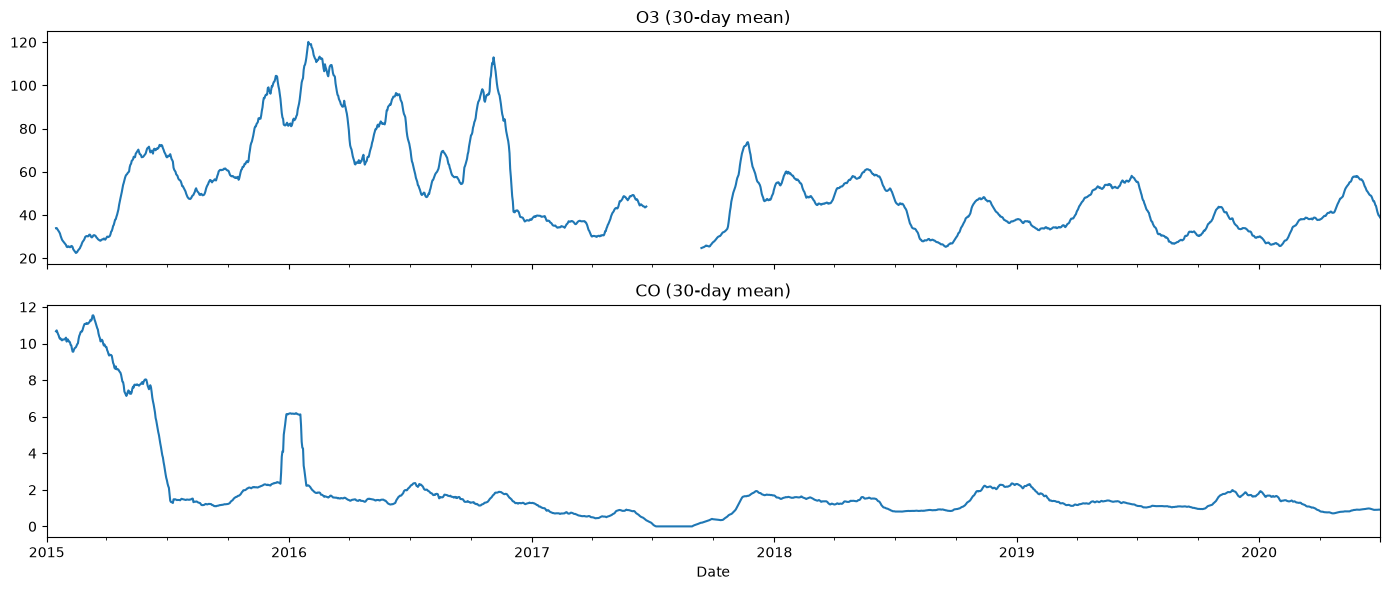

      NOx  CO  Benzene  Toluene
Date                           
2015    0   0        0        0
2016    0   0        0        0
2017    2  87        8      108
2018    0   0        0        0
2019    0   0        0        0
2020    0   0        0        0


In [3]:
import matplotlib.pyplot as plt

# 1) Where exactly does the shift happen?
m = df[["O3", "CO", "NO2", "PM2.5"]].resample("MS").mean().round(1)
print(m.loc["2016-06":"2017-06"])

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
df["O3"].rolling(30, min_periods=15).mean().plot(ax=axes[0], title="O3 (30-day mean)")
df["CO"].rolling(30, min_periods=15).mean().plot(ax=axes[1], title="CO (30-day mean)")
plt.tight_layout(); plt.show()

# 2) Are the zeros clustered in time?
zeros = (df[["NOx", "CO", "Benzene", "Toluene"]] == 0)
print(zeros.groupby(df.index.year).sum())

## 4. Zero readings and before/after comparison
All zeros fall between February and September 2017, so they are sensor placeholders.


In [4]:
# which dates are the zeros on?
for c in ["NOx", "CO", "Benzene", "Toluene"]:
    z = df.index[df[c] == 0]
    print(c, z.min().date(), "->", z.max().date(), len(z))

# do the other pollutants shift at the cutoff too?
cut = "2016-12-01"
pol = ["PM2.5", "PM10", "NO", "NO2", "NH3", "SO2", "O3", "Benzene", "Toluene"]
print(pd.DataFrame({
    "before_mean": df.loc[:cut, pol].mean(),
    "after_mean": df.loc[cut:, pol].mean(),
}).round(1))

NOx 2017-08-12 -> 2017-08-13 2
CO 2017-02-24 -> 2017-08-30 87
Benzene 2017-07-23 -> 2017-08-21 8
Toluene 2017-04-22 -> 2017-09-25 108
         before_mean  after_mean
PM2.5          123.5       113.9
PM10           236.8       230.8
NO              39.7        38.7
NO2             55.9        48.1
NH3             44.8        40.5
SO2             15.4        16.2
O3              68.4        41.6
Benzene          4.0         3.3
Toluene         11.7        20.1


## 5. Cleaning steps
Keep data from 2016-12-01, treat zeros as missing, remove the 2017-06-08 to 2017-09-25 outage, drop Xylene, City and AQI_Bucket, and interpolate gaps of up to 3 days only.


In [5]:
clean = df.loc["2016-12-01":].copy()

# zeros are placeholders, not real readings
zero_cols = ["NOx", "CO", "Benzene", "Toluene"]
clean[zero_cols] = clean[zero_cols].replace(0, np.nan)

# drop the long 2017 outage (covers the PM10, SO2 and O3 gaps)
outage = pd.date_range("2017-06-08", "2017-09-25")
clean = clean.loc[~clean.index.isin(outage)]

# drop columns we won't cluster on
clean = clean.drop(columns=["Xylene", "City", "AQI_Bucket"])   # AQI kept for profiling later

# fill only short gaps (up to 3 days)
pol = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene"]
clean[pol] = clean[pol].interpolate(method="time", limit=3, limit_area="inside")

print(clean.shape)
print(clean[pol].isna().sum())

(1199, 16)
PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
dtype: int64


## 6. Remove physically impossible readings
PM2.5 more than 1.5 times PM10 is not possible, since PM2.5 is part of PM10. Dropped: 2017-01-21, 2017-02-24, 2017-02-25, 2017-02-26 (threshold of 1.5 is a judgment call).

In [6]:
raw_ratio = clean["PM2.5"] / clean["PM10"]
bad_days = raw_ratio[raw_ratio > 1.5].index
print([d.date() for d in bad_days])
clean = clean.drop(index=bad_days)
print(clean.shape)        

[datetime.date(2017, 1, 21), datetime.date(2017, 2, 24), datetime.date(2017, 2, 25), datetime.date(2017, 2, 26)]
(1195, 16)


## 7. Consistency check and save


In [7]:
# consistency check within the cleaned period
print(clean.groupby(clean.index.year)[pol].mean().round(1))
print(clean[pol].describe().T[["min", "50%", "max"]].round(1))

# save (keep the Date index)
clean.to_csv(BASE / "data" / "cleaned" / "delhi_clean.csv")
print("saved", clean.shape)

      PM2.5   PM10    NO   NO2   NOx   NH3   CO   SO2    O3  Benzene  Toluene
Date                                                                         
2016  232.4  413.7  92.9  82.7  51.1  54.1  1.3  22.3  38.1      6.8     15.1
2017  156.6  290.1  59.9  63.6  46.4  49.4  1.0  24.1  44.1      3.5     11.1
2018  115.0  240.1  36.5  45.9  57.3  42.4  1.4  13.6  44.4      3.6     24.3
2019  108.5  215.0  32.1  45.2  53.2  36.4  1.4  14.0  38.9      3.8     28.9
2020   80.3  157.0  22.7  33.2  38.8  34.1  1.1  13.9  40.6      2.7     19.8
          min    50%    max
PM2.5    10.2   98.2  639.2
PM10     19.5  219.1  796.9
NO        4.4   29.4  221.0
NO2      14.4   46.4  131.6
NOx       1.9   44.4  195.8
NH3      12.1   38.6   99.2
CO        0.1    1.1    3.7
SO2       2.9   14.9   65.5
O3       14.9   39.8  110.7
Benzene   0.2    3.0   20.6
Toluene   1.3   18.8  103.0
saved (1195, 16)


## 8. Toluene and NOx consistency check
Toluene rises 5 to 10 times from mid-2018 while Benzene stays normal. NOx is often lower than NO2 in 2017. Both are excluded from clustering.

In [8]:
# any real zeros left?
print((clean[["CO","NOx","Benzene","Toluene"]] <= 0).sum())

# Toluene and NOx by month: find the break
t = clean[["Toluene", "NOx", "NO", "NO2", "Benzene"]].resample("MS").mean().round(1)
print(t)

# same-season comparison (Jan-May only), so years are comparable
jm = clean[clean.index.month.isin([1, 2, 3, 4, 5])]
print(jm.groupby(jm.index.year)[["Toluene", "NOx", "NO", "NO2", "Benzene", "PM2.5"]].mean().round(1))

CO         0
NOx        0
Benzene    0
Toluene    0
dtype: int64
            Toluene    NOx    NO   NO2  Benzene
Date                                           
2016-12-01     15.1   51.1  92.9  82.7      6.8
2017-01-01     10.8   48.2  84.8  67.9      5.1
2017-02-01      8.4   56.4  85.1  69.4      3.8
2017-03-01      6.6   36.5  55.6  58.5      3.0
2017-04-01     14.4   47.1  71.2  80.3      2.9
2017-05-01     15.4   42.3  53.2  69.6      2.8
2017-06-01     13.8   50.9  64.5  90.5      2.3
2017-07-01      NaN    NaN   NaN   NaN      NaN
2017-08-01      NaN    NaN   NaN   NaN      NaN
2017-09-01      1.6   18.3  31.9  28.6      0.3
2017-10-01      3.9   36.4  40.5  47.2      1.0
2017-11-01     15.6   85.8  48.8  60.7      5.8
2017-12-01     14.3   25.3  49.4  56.6      4.8
2018-01-01      8.8   32.5  38.3  51.8      3.6
2018-02-01      5.1   70.3  39.8  57.4      2.5
2018-03-01      4.4   60.8  30.0  46.6      2.6
2018-04-01      4.8   58.1  26.7  49.0      2.9
2018-05-01      4.5   5

## Summary of decisions
1. Removed data before December 2016 (O3 and CO level shifts).
2. Removed 8 June to 25 September 2017 (simultaneous sensor outage).
3. Treated zeros as missing (all in 2017).
4. Dropped Xylene (39% missing), City and AQI_Bucket.
5. Interpolated gaps of up to 3 days only.
6. Dropped 4 days with PM2.5 above 1.5 times PM10.

**Limitations:** autumn 2016 is excluded; the cause of the early-period inconsistency is unconfirmed.
